/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={


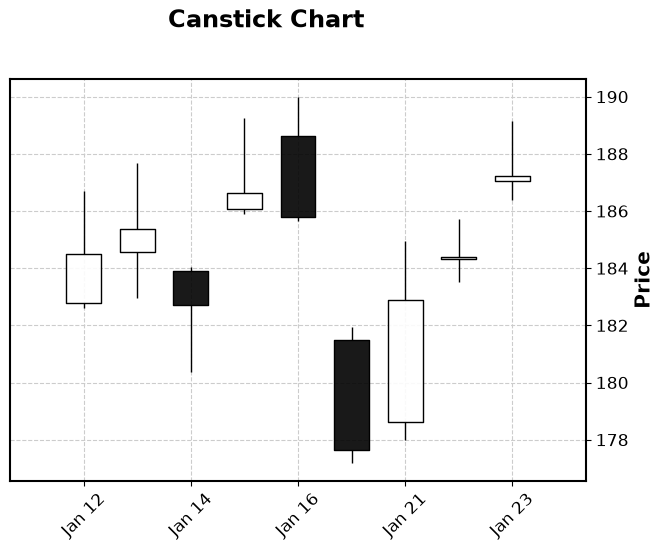

In [4]:
import yfinance as yf
import pandas as pd
import mplfinance as mpl

ticker = "NVDA"
data = yf.Ticker(ticker).history(start="2026-01-10",end="2026-01-25")
df = pd.DataFrame(data)
mpl.plot(df,type='candle',style='classic',title='Canstick Chart')

In [22]:
s = pd.Series(range(5))
t=s.rolling(window=3,min_periods=3).sum()
t


0    NaN
1    NaN
2    3.0
3    6.0
4    9.0
dtype: float64

In [23]:
for window in s.rolling(window=3):
    print(window)

0    0
dtype: int64
0    0
1    1
dtype: int64
0    0
1    1
2    2
dtype: int64
1    1
2    2
3    3
dtype: int64
2    2
3    3
4    4
dtype: int64


In [43]:
df = pd.DataFrame(range(5))
# t=df.rolling(window=len(df),min_periods=1).mean()
t=df.expanding(min_periods=1).mean()
t

,0
0,0.0
1,0.5
2,1.0
3,1.5
4,2.0


In [51]:
t=df.ewm(alpha=0.8,adjust=False).mean()
t

,0
0,0.0000
1,0.8000
2,1.7600
3,2.7520
4,3.7504


In [7]:
import pandas as pd

close = pd.Series([100, 102, 104, 103, 106, 109])
sma_3= close.rolling(window=3,min_periods=1).mean()

result = pd.DataFrame({
    "close":close,
    "sma_3":sma_3
})
# result=result.rolling(window=3).mean()
print(result.round(2))

   close   sma_3
0    100  100.00
1    102  101.00
2    104  102.00
3    103  103.00
4    106  104.33
5    109  106.00


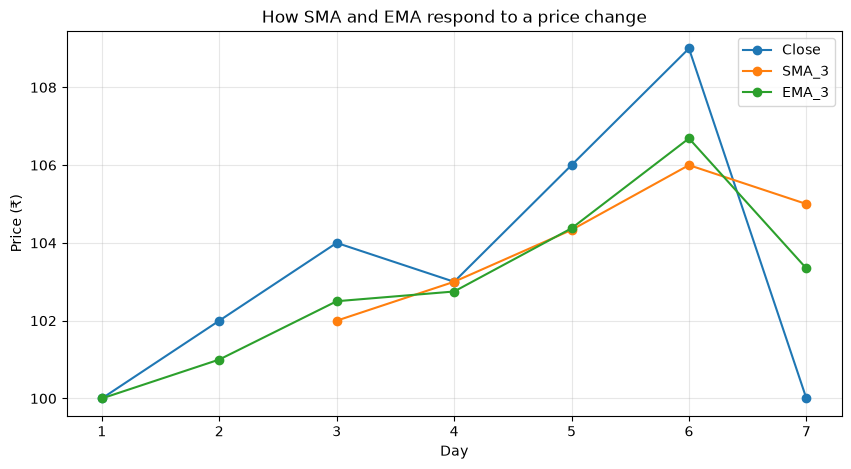

   Close   SMA_3   EMA_3  Distance_from_SMA  SMA_change
1    100     NaN  100.00                NaN         NaN
2    102     NaN  101.00                NaN         NaN
3    104  102.00  102.50               2.00         NaN
4    103  103.00  102.75               0.00        1.00
5    106  104.33  104.38               1.67        1.33
6    109  106.00  106.69               3.00        1.67
7    100  105.00  103.34              -5.00       -1.00


In [24]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Close":[100,102,104,103,106,109,100]})
df.index = range(1,len(df)+1)
df["SMA_3"] = df["Close"].rolling(window=3).mean()

df["EMA_3"] = df["Close"].ewm(span=3, adjust=False).mean()

# df["SMA_5"] = df["Close"].rolling(window=5).mean()
# df["EMA_5"] = df["Close"].ewm(span=5, adjust=False).mean()
# Plot each column as a separate line
df.plot(marker="o", figsize=(10, 5))

plt.title("How SMA and EMA respond to a price change")
plt.xlabel("Day")
plt.ylabel("Price (₹)")
plt.grid(alpha=0.3)
plt.show()

# Positive: price is above the SMA
# Negative: price is below the SMA
df["Distance_from_SMA"] = df["Close"] - df["SMA_3"]

# Current SMA minus the previous row's SMA
df["SMA_change"] = df["SMA_3"].diff()
print(df.round(2))

     Close   SMA_3  SMA_5  Bullish_cross  Bearish_cross   Signal
Day                                                             
1      100     NaN    NaN          False          False         
2      102     NaN    NaN          False          False         
3      104  102.00    NaN          False          False         
4      103  103.00    NaN          False          False         
5      106  104.33  103.0          False          False         
6      109  106.00  104.8          False          False         
7      100  105.00  104.4          False          False         
8       96  101.67  102.8          False           True  Bearish
9       94   96.67  101.0          False          False         
10      98   96.00   99.4          False          False         
11     102   98.00   98.0          False          False         
12     106  102.00   99.2           True          False  Bullish
13     110  106.00  102.0          False          False         


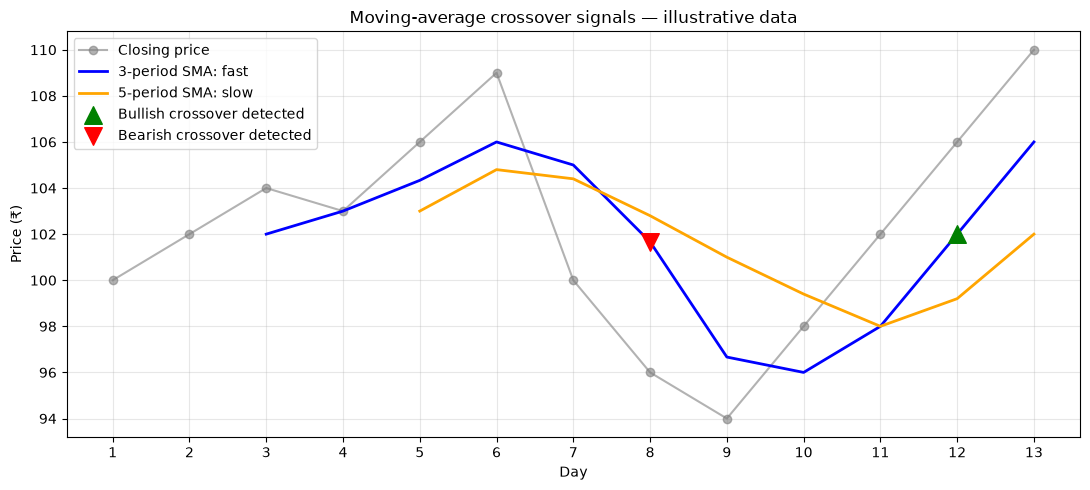

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Illustrative prices—not real market data
df = pd.DataFrame({
    "Close": [
        100, 102, 104, 103, 106, 109, 100,  # Your original data
        96, 94, 98, 102, 106, 110           # Additional observations
    ]
})

df.index = range(1, len(df) + 1)
df.index.name = "Day"

# 1. Calculate the moving averages
df["SMA_3"] = df["Close"].rolling(window=3).mean()
df["SMA_5"] = df["Close"].rolling(window=5).mean()

fast = df["SMA_3"]
slow = df["SMA_5"]

# 2. Detect changes in their relationship
df["Bullish_cross"] = (
    (fast > slow)
    & (fast.shift(1) <= slow.shift(1))
)

df["Bearish_cross"] = (
    (fast < slow)
    & (fast.shift(1) >= slow.shift(1))
)

# 3. Add a readable signal label
df["Signal"] = ""
df.loc[df["Bullish_cross"], "Signal"] = "Bullish"
df.loc[df["Bearish_cross"], "Signal"] = "Bearish"

# Display every row
print(df.round(2).to_string())

# 4. Select only the rows where a signal occurred
bullish = df.loc[df["Bullish_cross"]]
bearish = df.loc[df["Bearish_cross"]]

# 5. Plot prices and both averages
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    df.index, df["Close"],
    color="gray", marker="o", alpha=0.6, label="Closing price"
)
ax.plot(
    df.index, df["SMA_3"],
    color="blue", linewidth=2, label="3-period SMA: fast"
)
ax.plot(
    df.index, df["SMA_5"],
    color="orange", linewidth=2, label="5-period SMA: slow"
)

# Mark the fast SMA on the day each signal is detected
ax.scatter(
    bullish.index, bullish["SMA_3"],
    marker="^", color="green", s=160,
    label="Bullish crossover detected", zorder=5
)
ax.scatter(
    bearish.index, bearish["SMA_3"],
    marker="v", color="red", s=160,
    label="Bearish crossover detected", zorder=5
)

ax.set_title("Moving-average crossover signals — illustrative data")
ax.set_xlabel("Day")
ax.set_ylabel("Price (₹)")
ax.set_xticks(df.index)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()